# Examples of TEC MCMC-based detrending

## Fit one TEC curve

In [1]:
import pytensor
pytensor.config.cxx = ""   # no C compiler needed

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from tec_mcmc import (
    SamplerConfig,
    fit_curve,
    load_tec_csv,
    prepare_curve,
    split_model_components,
    unpack_parameter_matrix,
)

In [14]:
# Path to the data csv where the first column is the time column in seconds
# and the other columns are TEC time series
DATA = Path("../../Data/tec_vert_no_SZA_20170907_El_10_90_Lat_15_60_Lon_90_90_SSA_30_90min.csv") 

# Times in minutes where significant solar flares took place
T_PEAKS_SOLAR = np.array([302., 454., 594., 615., 873., 876., 880., 891., 993., 1123., 1308.])

# load data
curves = load_tec_csv(DATA)

# Pick a curve: 0-based curve number == IDL loop index i (CSV column i+2).
CURVE = 510

print(len(curves), f"curves; this one (ID = {CURVE}) has", len(curves[CURVE][0]), "finite samples")

# set random generator
rng = np.random.default_rng(CURVE)   # dummy-flare placement (IDL used RANDOMU)

# Select the chosen curve
t_abs, y_raw = curves[CURVE]

# Collapse plateaus and shift time to 0
t, y, flare_idx, true_idx, t0 = prepare_curve(t_abs, y_raw, T_PEAKS_SOLAR, rng=rng)

print("true flares in window :", t[true_idx] + t0)
print("flare indices fitted  :", flare_idx, "(last one is a dummy if < 3 true flares)")

2380 curves; this one (ID = 450) has 229 finite samples
true flares in window : [873. 876. 880. 891.]
flare indices fitted  : [ 65  71  79 101] (last one is a dummy if < 3 true flares)


In [16]:
# configure MCMC
config = SamplerConfig(
    draws=100_000, tune=100_000,   # ~several mins per curve; use 20_000 for quick looks
    chains=4, cores=1, sampler="demetropolisz", random_seed=42,
    n_starts=30,                   # multi-start least squares to seed the chains
)

# Fit the curve
result = fit_curve(t, y, flare_idx, config=config)

print("best-fit source :", result.map_source)
print("sigma (best fit):", round(result.sigma_map, 4))
print("log-likelihood  :", round(result.map_log_likelihood, 1))
for k, v in result.diagnostics.items():
    print(f"  {k:32s} {v:.3f}" if isinstance(v, float) else f"  {k:32s} {v}")

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: 
RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),

Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws total) took 53 seconds.


best-fit source : optimizer
sigma (best fit): 0.0619
log-likelihood  : 312.3
  rhat_curves_max                  1.323
  ess_curves_min                   466.466
  rhat_params_max                  2.848
  ess_params_min                   228.235
  trend_chain_spread_over_sigma    2.642
  flares_chain_spread_over_sigma   2.646
  model_chain_spread_over_sigma    1.435
  converged                        False


**Reading the diagnostics.**

* `rhat_params_max` – R-hat over the individual parameters. Expect it to stay well above 1: several different sets of four sinusoids describe the same smooth 2-hour trend, and two nearby-period sinusoids with large opposite amplitudes can cancel, so single parameters are not identifiable.
* `rhat_curves_max`, `ess_curves_min` – the same statistics for the quantities actually used: the trend, the summed flares and the full model on a 25-point time grid, plus `sigma`. `converged` is `True` when R-hat < 1.05 and ESS > 100 for all of these.

* `*_chain_spread_over_sigma` – the largest gap between the four chains' mean curves, in units of the noise sigma. A `model_chain_spread_over_sigma` well below 1 means the fitted curve agrees across chains to a fraction of the noise. When the trend and flare spreads are larger than the model spread, the trend/flare *split* is uncertain: the sinusoids can absorb part of a flare. That is real posterior uncertainty, not a sampler bug.

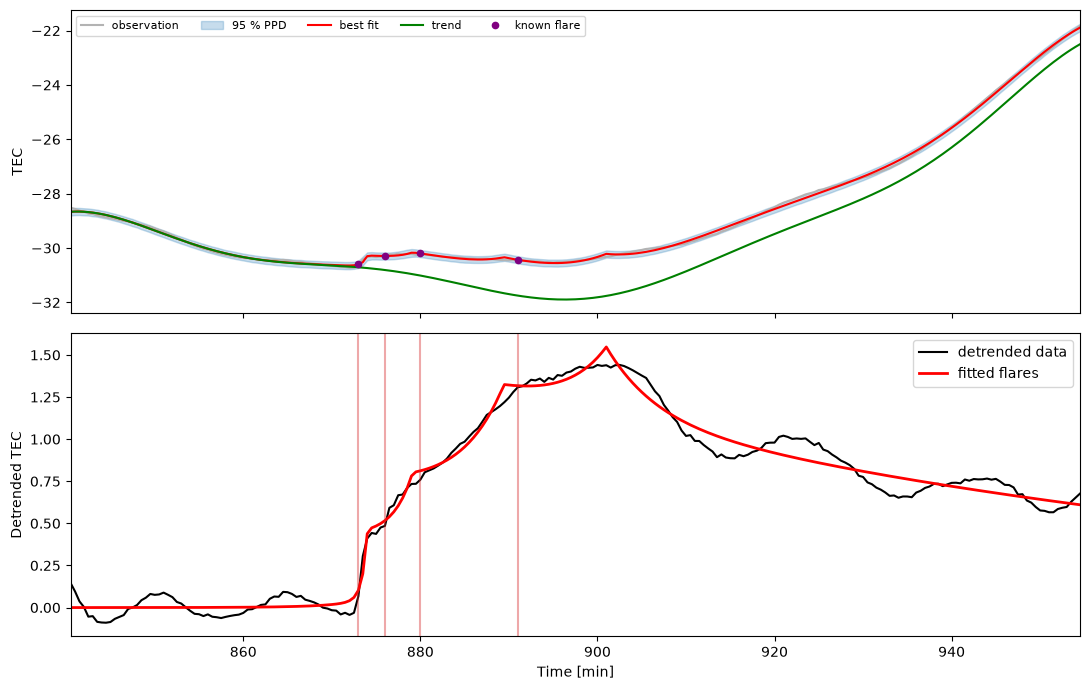

In [18]:
# Plot the results
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t_abs, y_raw, color="0.7", label="observation")
ax[0].fill_between(t + t0, result.ppd_lower, result.ppd_upper, color="C0", alpha=0.25, label="95 % PPD")
ax[0].plot(t + t0, result.map_model, "r", label="best fit")
ax[0].plot(t + t0, result.map_trend, "g", label="trend")
ax[0].plot((t + t0)[true_idx], result.map_model[true_idx], ".", color="purple", ms=9, label="known flare")
ax[0].set_ylabel("TEC"); ax[0].legend(ncol=5, fontsize=8)

ax[1].plot(t + t0, y - result.map_trend, "k", label="detrended data")
ax[1].plot(t + t0, result.map_flares, "r", lw=2, label="fitted flares")

for tp in T_PEAKS_SOLAR:
    ax[1].axvline(tp, color="C3", alpha=0.4)
ax[1].set_xlim(t_abs.min(), t_abs.max())
ax[1].set_xlabel("Time [min]"); ax[1].set_ylabel("Detrended TEC"); ax[1].legend()
fig.tight_layout()

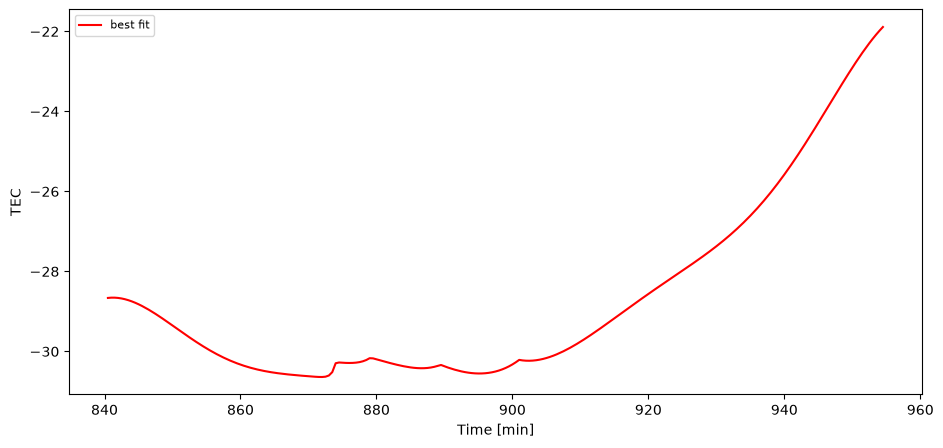

In [19]:
# Plot the model based on the best parameters
theta = result.map_params # best-fit parameters

background, flares = split_model_components(t, theta, result.n_flares)

fig, ax = plt.subplots(1, 1, figsize=(11, 5))
ax.plot(t + t0, background+flares, "r", label="best fit")
ax.set_ylabel("TEC")
ax.set_xlabel("Time [min]")
ax.legend(ncol=5, fontsize=8)

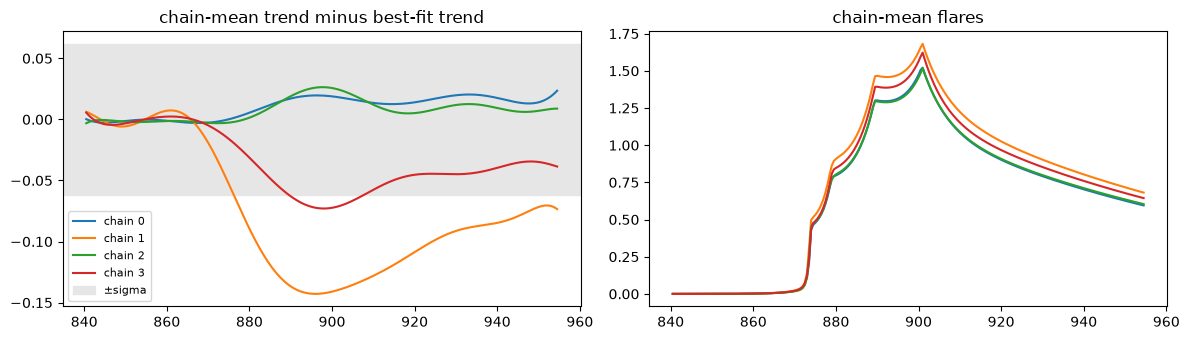

In [20]:
# Do the chains agree?  Mean trend / flares per chain (posterior rows are chain-major).

S = result.posterior_samples.reshape(config.chains, -1, result.posterior_samples.shape[1])
n_model = S.shape[2] - 1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for c in range(config.chains):
    rows = S[c, :: max(1, S.shape[1] // 500)]
    comps = np.array([split_model_components(t, r[:n_model], result.n_flares) for r in rows])
    ax[0].plot(t + t0, comps[:, 0].mean(0) - result.map_trend, label=f"chain {c}")
    ax[1].plot(t + t0, comps[:, 1].mean(0), label=f"chain {c}")
ax[0].axhspan(-result.sigma_map, result.sigma_map, color="0.9", label="±sigma")
ax[0].set_title("chain-mean trend minus best-fit trend"); ax[1].set_title("chain-mean flares")
ax[0].legend(fontsize=8); fig.tight_layout()

In [9]:
# Posterior summary of the physical parameters (columns follow the IDL/SoBAT order)
u = unpack_parameter_matrix(result.posterior_samples, result.n_flares)
for k, v in u.items():
    print(f"{k:20s} median", np.round(np.median(v, axis=0), 3))

offset               median 105.31
harmonic_amplitude   median [16.367 21.7   28.06  51.905]
harmonic_period      median [ 58.249  63.512 181.546 314.964]
harmonic_phase       median [ 1.247 -1.331 -1.487  2.088]
sigma                median 0.06
flare_amplitude      median [0.    0.83  0.223]
flare_peak_time      median [56.377 78.262 12.706]
flare_rise_time      median [4.952 0.914 4.93 ]
flare_decay_time     median [21.938  3.077 77.094]


## Fit all the curves

Fits curves in parallel (one PyMC core per worker) and writes the best-fit parameters of every curve to one JSON file; see `help(fit_tec_csv)` for its layout. The file is rewritten every `SAVE_EVERY` curves and finished curves are skipped, so an interrupted run resumes when this cell is run again. For the full set (~2400 curves) keep the Mac awake, e.g. run `caffeinate -i` in a terminal.

In [17]:
import os

# Set before the worker processes start; they inherit these.
os.environ["PYTENSOR_FLAGS"] = "cxx="      # no C compiler needed
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(v, "1")          # one thread per worker
os.environ["PYTHONWARNINGS"] = (
    "ignore:Loop fusion failed:UserWarning,"
    "ignore:overflow encountered in exp:RuntimeWarning"
)

from pathlib import Path
import numpy as np
from tec_mcmc import SamplerConfig, fit_tec_csv

In [19]:
# Path to the data csv where the first column is the time column in seconds
# and the other columns are TEC time series
CSV_PATH = Path("../../Data/tec_vert_no_SZA_20170907_El_10_90_Lat_15_60_Lon_90_90_SSA_30_90min.csv") 

# Times in minutes where significant solar flares took place
T_PEAKS_SOLAR = np.array([302., 454., 594., 615., 873., 876., 880., 891., 993., 1123., 1308.])

# Output path
OUT_JSON = Path("tec_mcmc_results/map_params.json")   # rerunning resumes: curves already in it are skipped

# Configure multiprocessing
MAX_WORKERS = 4      # number of performance cores
CURVES = 4          # None = all curves, an int n = the first n curves, or a list of curve ids
SAVE_EVERY = 10      # rewrite the JSON after this many new results

# Configure MCMC
CONFIG = SamplerConfig(
    draws=100_000, tune=100_000, chains=4, cores=1,
    sampler="demetropolisz", random_seed=42, n_starts=30,
    progressbar=False,
)


In [21]:
results = fit_tec_csv(
    CSV_PATH, OUT_JSON, T_PEAKS_SOLAR,
    config=CONFIG, curves=CURVES, max_workers=MAX_WORKERS, save_every=SAVE_EVERY,
)

4 curves to fit, 0 already done


Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws total) took 50 seconds.
Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws total) took 53 seconds.
Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws tota

[1/4] curve 1 done, ~3 min left


Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws total) took 58 seconds.


[2/4] curve 3 done, ~1 min left
[3/4] curve 0 done, ~0 min left
[4/4] curve 2 done, ~0 min left
saved 4 curves to tec_mcmc_results/map_params.json (1.4 min)
